# Detección de piletas — YOLOv5n
Notebook generado desde visionxcomputadora.py (una celda por etapa). Ejecutar en orden con GPU T4.

In [1]:
# ============================================================================
# Detección de piletas en imágenes satelitales — YOLOv5n (modelo único, 1 clase)
# 12 etapas. Pensado para Google Colab con GPU T4 (tier gratis).
# Ejecutar de arriba hacia abajo, una etapa por vez.
# ============================================================================

# ---------------- CONFIG GLOBAL (la usan todas las etapas) ----------------
import os
from pathlib import Path

SEED = 42
IMG_SIZE = 320          # resolución de entrenamiento/inferencia (liviano para T4)
BATCH = 8
EPOCHS = 25
PATIENCE = 6            # early stopping: corta si el val no mejora en 6 épocas
CONF_DEFAULT = 0.5      # umbral de confianza por defecto (la Etapa 5 calcula el óptimo)

BASE = Path("/content")
RUNS_DIR = BASE / "runs"
RES_DIR = BASE / "resultados"
YOLO_DATA = BASE / "yolo_data"
YAML_PATH = YOLO_DATA / "data.yaml"

YOLO_PILETA = 0   # único id de clase en formato YOLO
NOMBRES_CLASES = ["pileta"]
# NOTA: el mapeo XML -> YOLO se define en la Etapa 2 (CLASE_PILETA_XML)
# después de verificar a ojo la grilla de la EDA.


# ================= ETAPA 1 · Entorno, GPU y descarga automática =================
# Qué hace: deja Colab listo (GPU, librerías, semillas) y baja el dataset solo.
import subprocess, sys, random

# subprocess en vez de !pip: funciona igual en .py y en celdas del notebook.
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                       "kagglehub", "ultralytics", "albumentations",
                       "torchmetrics", "thop", "onnx", "onnxruntime"])

import torch
import numpy as np

print("CUDA disponible:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    # Entrenar un detector en CPU tarda horas por época: se frena acá con
    # instrucciones en vez de quemar tiempo. Para inferencia suelta sí sirve CPU.
    raise SystemExit("Sin GPU. Activá GPU T4 en Entorno > Cambiar tipo de entorno y reejecutá.")
DEVICE = 0  # índice de GPU para ultralytics

print("torch:", torch.__version__)
import ultralytics, albumentations, torchmetrics
print("ultralytics:", ultralytics.__version__)
print("albumentations:", albumentations.__version__)
print("torchmetrics:", torchmetrics.__version__)

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
set_seed()

# Descarga 100% automática, sin kaggle.json ni clics (dataset público).
import kagglehub
RUTA_DATASET = Path(kagglehub.dataset_download("kbhartiya83/swimming-pool-and-car-detection"))
print("Dataset en:", RUTA_DATASET)

for d in [RUNS_DIR, RES_DIR, YOLO_DATA]:
    d.mkdir(parents=True, exist_ok=True)

# Árbol (2 niveles) + conteo de imágenes por carpeta.
for root, dirs, files in os.walk(RUTA_DATASET):
    nivel = len(Path(root).relative_to(RUTA_DATASET).parts)
    if nivel > 2:
        continue
    n_img = sum(1 for f in files if f.lower().endswith((".jpg", ".jpeg", ".png")))
    print("  " * nivel + f"{Path(root).name}/  ({n_img} imágenes)")




CUDA disponible: True
GPU: Tesla T4
torch: 2.11.0+cu128
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
ultralytics: 8.4.164
albumentations: 2.0.8
torchmetrics: 1.9.0


100%|██████████| 111M/111M [00:03<00:00, 34.8MB/s]

Extracting files...


Dataset en: /root/.cache/kagglehub/datasets/kbhartiya83/swimming-pool-and-car-detection/versions/1
1/  (0 imágenes)
  training_data/  (0 imágenes)
    training_data/  (0 imágenes)
  test_data_images/  (0 imágenes)
    test_data_images/  (0 imágenes)


Archivos XML encontrados: 3748
        image_id   xmin    ymin   xmax    ymax class
0  000000000.jpg  58.47  152.31  69.58  163.43     1
1  000000000.jpg  10.32  205.68  21.43  216.80     1
2  000000000.jpg  40.37    0.00  50.97    3.89     1
3  000000000.jpg  46.67   41.29  57.79   52.40     1
4  000000001.jpg  58.47   40.31  69.58   51.43     1
Clases crudas en los XML: ['1', '2']
Conteo por clase:
 class
1    13022
2     3150
Name: count, dtype: int64
Imágenes anotadas: 3748 | Anotaciones: 16172
Ejemplo de imagen localizada: /root/.cache/kagglehub/datasets/kbhartiya83/swimming-pool-and-car-detection/versions/1/training_data/training_data/images/000000000.jpg
Mapeo fijado: XML '2' -> YOLO 0 (pileta). Resto de clases se descartan.


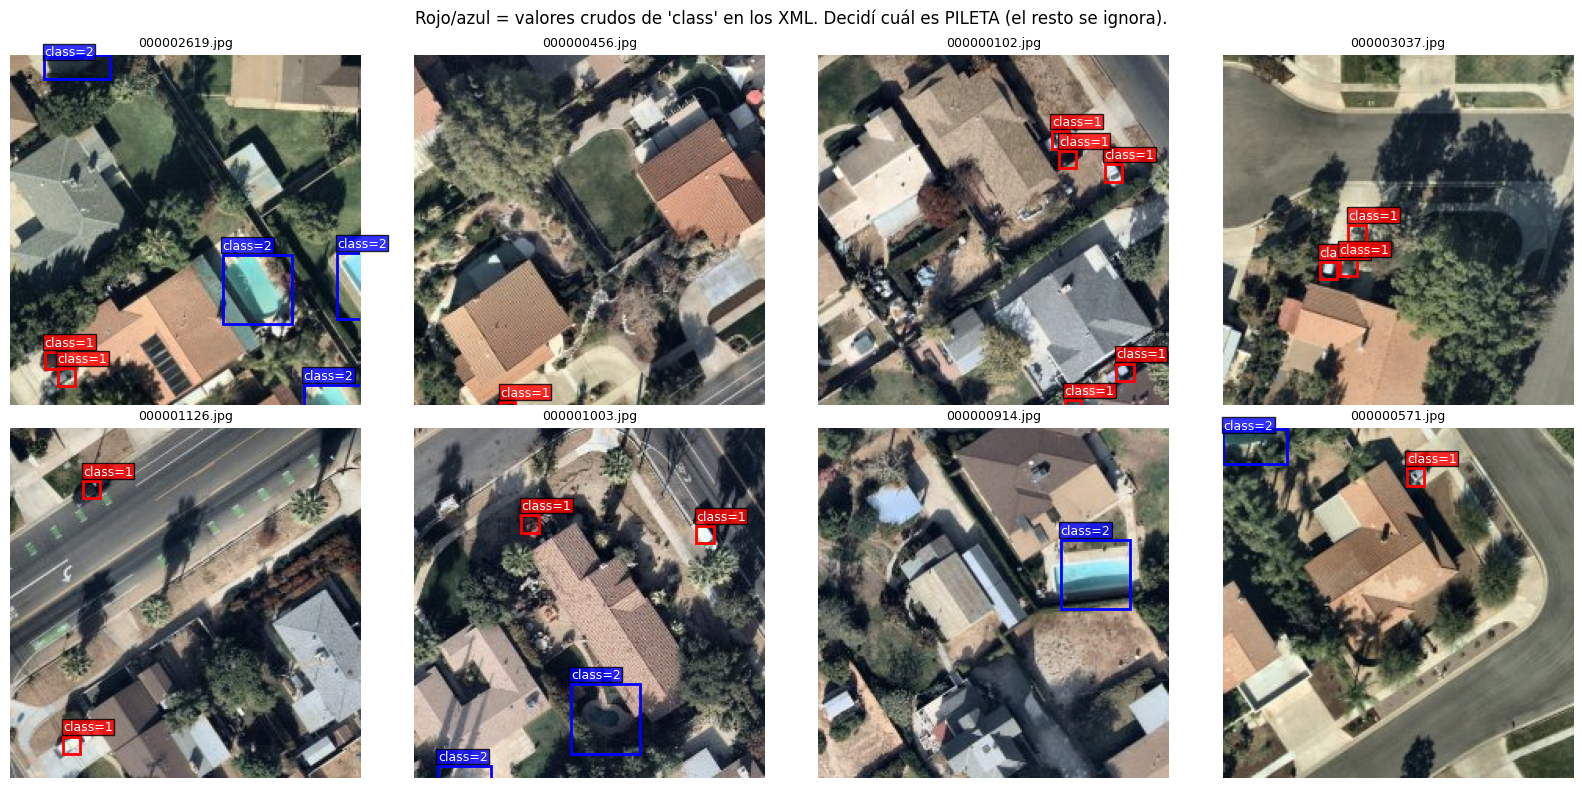

In [3]:
import glob
import xml.etree.ElementTree as ET
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches

xmls = sorted(glob.glob(str(RUTA_DATASET / "**" / "*.xml"), recursive=True))
print(f"Archivos XML encontrados: {len(xmls)}")

def parsear_xml(path_xml):
    """Devuelve (nombre_imagen, ancho, alto, lista de (clase_cruda, xmin, ymin, xmax, ymax))."""
    t = ET.parse(path_xml).getroot()
    nombre = t.findtext("filename")
    sz = t.find("size")
    w, h = int(sz.findtext("width")), int(sz.findtext("height"))
    objs = []
    for o in t.findall("object"):
        c = (o.findtext("name") or "").strip()
        b = o.find("bndbox")
        objs.append((c, float(b.findtext("xmin")), float(b.findtext("ymin")),
                     float(b.findtext("xmax")), float(b.findtext("ymax"))))
    return nombre, w, h, objs

filas = []
info_imgs = {}  # nombre -> (ancho, alto, ruta_xml)
for x in xmls:
    nombre, w, h, objs = parsear_xml(x)
    info_imgs[nombre] = (w, h, x)
    for c, x1, y1, x2, y2 in objs:
        filas.append({"image_id": nombre, "xmin": x1, "ymin": y1,
                      "xmax": x2, "ymax": y2, "class": c})
df_anot = pd.DataFrame(filas)
print(df_anot.head())
print("Clases crudas en los XML:", sorted(df_anot["class"].unique()))
print("Conteo por clase:\n", df_anot["class"].value_counts())
print(f"Imágenes anotadas: {len(info_imgs)} | Anotaciones: {len(df_anot)}")

# Dónde están físicamente las imágenes (misma carpeta de los XML o vecina).
def localizar_imagen(nombre):
    img_stem = Path(nombre).stem
    image_extensions = [".jpg", ".jpeg", ".png", ".JPG"]

    # Explicitly define potential image directories based on dataset structure
    potential_image_dirs = [
        Path(xmls[0]).parent.parent / "images", # e.g., .../training_data/training_data/images
        RUTA_DATASET / "training_data" / "training_data" / "images",
        RUTA_DATASET / "test_data_images" / "test_data_images" / "images",
        RUTA_DATASET # Fallback for images directly in root
    ]

    for base_dir in potential_image_dirs:
        if base_dir.is_dir():
            for ext in image_extensions:
                cand = base_dir / (img_stem + ext)
                if cand.is_file():
                    return cand

    # If not found through structured paths, then perform a recursive glob search,
    # but strictly filter by known image extensions. This prevents picking up XMLs.
    cands = []
    for ext in image_extensions:
        cands.extend(glob.glob(str(RUTA_DATASET / "**" / img_stem) + ext, recursive=True))

    if cands:
        return Path(cands[0]) # Return the first found image file

    return None # Return None if no image file is found after all attempts

ruta_ej = localizar_imagen(next(iter(info_imgs)))
print("Ejemplo de imagen localizada:", ruta_ej)

# Grilla 2x4: cada clase cruda con un color. MIRÁ esta grilla antes de seguir.
clases = sorted(df_anot["class"].unique())
colores = {"__0__": "red", "__1__": "blue", "__2__": "green", "__3__": "orange"}
color_de = {c: colores.get(f"__{i}__", "magenta") for i, c in enumerate(clases)}
import random as _rnd
_rnd.seed(SEED)
muestra = _rnd.sample(sorted(info_imgs), min(8, len(info_imgs)))
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, nombre in zip(axes.flat, muestra):
    r = localizar_imagen(nombre)
    ax.imshow(np.array(Image.open(r).convert("RGB")))
    for _, f in df_anot[df_anot.image_id == nombre].iterrows():
        ax.add_patch(patches.Rectangle((f.xmin, f.ymin), f.xmax - f.xmin, f.ymax - f.ymin,
                                       fill=False, edgecolor=color_de[f["class"]], linewidth=2))
        ax.text(f.xmin, max(0, f.ymin - 4), f'class={f["class"]}', fontsize=9,
                color="white", bbox=dict(facecolor=color_de[f["class"]], alpha=0.8, pad=1))
    ax.set_title(nombre, fontsize=9)
    ax.axis("off")
fig.suptitle("Rojo/azul = valores crudos de 'class' en los XML. Decidí cuál es PILETA (el resto se ignora).",
             fontsize=12)
fig.tight_layout()
fig.savefig(RES_DIR / "eda_ejemplos.png", dpi=120)

# ---- VERIFICACIÓN MANUAL (único paso no automático) ----
# Mirá la grilla y asigná. Pista: las piletas son rectángulos grandes junto
# a casas, pocas por imagen. El resto de clases se ignora.
CLASE_PILETA_XML = "2"    # <- clase cruda de las PILETAS (ajustar si la grilla dice otra)
assert CLASE_PILETA_XML in set(df_anot["class"]), "CLASE_PILETA_XML no existe en los datos"
print(f"Mapeo fijado: XML {CLASE_PILETA_XML!r} -> YOLO {YOLO_PILETA} (pileta). "
      f"Resto de clases se descartan.")

In [4]:
# ================= ETAPA 3 · Split + conversión a formato YOLO =================
# Qué hace: divide 70/15/15 estratificado por presencia de pileta y genera la
# estructura images/{train,val,test} + labels/{train,val,test} + data.yaml.
import shutil
from sklearn.model_selection import train_test_split

por_img = {}
for _, f in df_anot.iterrows():
    e = por_img.setdefault(f.image_id, {"pileta": False})
    if f["class"] == CLASE_PILETA_XML:
        e["pileta"] = True
df_img = pd.DataFrame([{"image_id": k, "tiene_pileta": int(v["pileta"])} for k, v in por_img.items()])
df_img["strat_key"] = df_img.tiene_pileta.astype(str)
print("Distribución por presencia de pileta:\n", df_img.strat_key.value_counts())
print("Imágenes con pileta:", df_img.tiene_pileta.sum(), "de", len(df_img))

def split_seguro(df):
    # stratify revienta si alguna combinación tiene <2 muestras: fallback sin estratificar.
    if (df.strat_key.value_counts() < 2).any():
        print("Aviso: combinación de clases muy rara, split sin estratificar.")
        return train_test_split(df, test_size=0.30, random_state=SEED)
    return train_test_split(df, test_size=0.30, random_state=SEED, stratify=df.strat_key)

# split_seguro devuelve (70 %, 30 %). El 30 % se parte despues en val y test.
# BUG CORREGIDO: antes se partia a la mitad el 70 % (quedaba 35/35/30 en vez de 70/15/15).
df_train, temp = split_seguro(df_img)
if (temp.strat_key.value_counts() < 2).any():
    df_val, df_test = train_test_split(temp, test_size=0.50, random_state=SEED)
else:
    df_val, df_test = train_test_split(temp, test_size=0.50, random_state=SEED,
                                       stratify=temp.strat_key)
n_tot = len(df_img)
print(f"Train: {len(df_train)} ({100 * len(df_train) / n_tot:.1f} %) | "
      f"Val: {len(df_val)} ({100 * len(df_val) / n_tot:.1f} %) | "
      f"Test: {len(df_test)} ({100 * len(df_test) / n_tot:.1f} %)")
# Controles: proporciones correctas y sin solapamiento entre splits.
assert abs(len(df_train) / n_tot - 0.70) < 0.02, "El train no quedo en 70 %"
assert abs(len(df_val) / n_tot - 0.15) < 0.02, "El val no quedo en 15 %"
assert abs(len(df_test) / n_tot - 0.15) < 0.02, "El test no quedo en 15 %"
s_tr, s_va, s_te = set(df_train.image_id), set(df_val.image_id), set(df_test.image_id)
assert not (s_tr & s_va) and not (s_tr & s_te) and not (s_va & s_te), "Splits solapados" 
for n, d in [("train", df_train), ("val", df_val), ("test", df_test)]:
    sub = df_anot[df_anot.image_id.isin(set(d.image_id))]
    print(f"{n}: piletas={(sub['class'] == CLASE_PILETA_XML).sum()} "
          f"(otras clases descartadas={(sub['class'] != CLASE_PILETA_XML).sum()})")

# Conversión XML -> YOLO txt (coordenadas normalizadas 0-1, tamaño real de cada imagen).
# Solo piletas: el resto de clases se ignora para minimizar el modelo (nc=1).
a_yolo = {CLASE_PILETA_XML: YOLO_PILETA}
for split, d in [("train", df_train), ("val", df_val), ("test", df_test)]:
    (YOLO_DATA / "images" / split).mkdir(parents=True, exist_ok=True)
    (YOLO_DATA / "labels" / split).mkdir(parents=True, exist_ok=True)
    for nombre in d.image_id:
        src = localizar_imagen(nombre)
        assert src is not None, f"No se encontró la imagen {nombre}"
        shutil.copy2(src, YOLO_DATA / "images" / split / (Path(nombre).stem + src.suffix))
        with Image.open(src) as im:
            W, H = im.size
        lineas = []
        for _, f in df_anot[df_anot.image_id == nombre].iterrows():
            if f["class"] not in a_yolo:
                continue
            cx = ((f.xmin + f.xmax) / 2) / W
            cy = ((f.ymin + f.ymax) / 2) / H
            w, h = (f.xmax - f.xmin) / W, (f.ymax - f.ymin) / H
            lineas.append(f"{a_yolo[f['class']]} {cx:.6f} {cy:.6f} {w:.6f} {h:.6f}")
        (YOLO_DATA / "labels" / split / (Path(nombre).stem + ".txt")).write_text("\n".join(lineas))
YAML_PATH.write_text(
    f"path: {YOLO_DATA}\ntrain: images/train\nval: images/val\ntest: images/test\n"
    f"nc: 1\nnames: ['pileta']\n")
print("data.yaml:\n", YAML_PATH.read_text())
# Verificación: los boxes convertidos tienen que sumar lo mismo que los XML del split.
for split, d in [("train", df_train), ("val", df_val), ("test", df_test)]:
    n_txt = sum(1 for t in (YOLO_DATA / "labels" / split).glob("*.txt")
                for _ in t.read_text().splitlines() if _.strip())
    n_xml = (df_anot[df_anot.image_id.isin(set(d.image_id))]["class"].isin(a_yolo)).sum()
    print(f"{split}: boxes en txt={n_txt} vs XML={n_xml} -> {'OK' if n_txt == n_xml else 'REVISAR'}")




Distribución por presencia de pileta:
 strat_key
1    1993
0    1755
Name: count, dtype: int64
Imágenes con pileta: 1993 de 3748
Train: 1311 | Val: 1312 | Test: 1125
train: piletas=1134 (otras clases descartadas=3860)
val: piletas=1088 (otras clases descartadas=4925)
test: piletas=928 (otras clases descartadas=4237)
data.yaml:
 path: /content/yolo_data
train: images/train
val: images/val
test: images/test
nc: 1
names: ['pileta']

train: boxes en txt=1134 vs XML=1134 -> OK
val: boxes en txt=1088 vs XML=1088 -> OK
test: boxes en txt=928 vs XML=928 -> OK


In [5]:
# ================= ETAPA 4 · Entrenamiento YOLOv5n =================
# Qué hace: fine-tuning desde pesos COCO (yolov5nu.pt) con early stopping y AMP
# automático de ultralytics. Es el modelo más chico (~2.5M params) y rápido.
import time
from ultralytics import YOLO

modelo = YOLO("yolov5nu.pt")  # se descarga solo la primera vez
t0 = time.time()
modelo.train(data=str(YAML_PATH), imgsz=IMG_SIZE, batch=BATCH, epochs=EPOCHS,
             patience=PATIENCE, seed=SEED, workers=2, device=DEVICE,
             project=str(RUNS_DIR), name="yolov5n", exist_ok=True, verbose=True)
print(f"Tiempo total de entrenamiento: {(time.time() - t0) / 60:.1f} min")
BEST_PT = RUNS_DIR / "yolov5n" / "weights" / "best.pt"
RESULTS_CSV = RUNS_DIR / "yolov5n" / "results.csv"
assert BEST_PT.exists(), "No se generó best.pt, revisar el log de entrenamiento"
print("Mejor checkpoint:", BEST_PT)




Ultralytics 8.4.164 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_data/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov5nu.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov5n, nbs=64, nms=None, opset=None, optimize=False, optimi

In [ ]:
# ================= ETAPA 4B · Experimento: capas congeladas vs no congeladas ==========
# Qué hace: entrena la MISMA arquitectura con 3 estrategias de transfer learning y
# compara mAP, tiempo por época, memoria de GPU y parámetros entrenables.
# Por qué: sin esto, la sección de capas congeladas del informe es solo teoría.
#
# COSTO: 3 entrenamientos. En T4 con ~2.600 imágenes de train y 25 épocas son
# ~20-30 min cada uno (60-90 min en total). Para una corrida rápida de prueba,
# bajar EPOCHS_FREEZE (siguen siendo comparables entre sí, pero no con la Etapa 4).

# OJO: /content es efimero. Si Colab se desconecta se pierde TODO lo no descargado.
# Esta etapa guarda el CSV despues de cada corrida y copia los results.csv a
# resultados/freeze_runs/ para que entren en el ZIP de la Etapa 11.
CORRER_FREEZE = True       # poné False para saltear esta etapa
EPOCHS_FREEZE = EPOCHS     # mismas épocas que la Etapa 4 para que sea comparable

# freeze de ultralytics congela los primeros N módulos del modelo:
# yolov5nu tiene 25 modulos (0..24) y Detect es el 24 (verificado cargando el modelo).
#   0  -> no congela nada              (fine-tuning completo, 100 % entrenable)
#   10 -> congela el backbone          (entrena neck + head, ~61 %)
#   24 -> congela backbone + neck      (entrena solo Detect, ~34 %)
# OJO: freeze=25 dejaria 0 parametros entrenables y ultralytics aborta con RuntimeError.
CONFIGS = [
    ("completo", 0, "Fine-tuning completo: toda la red se adapta"),
    ("backbone", 10, "Backbone congelado: se entrenan neck y head"),
    ("solo_cabeza", 24, "Backbone + neck congelados: solo la cabeza Detect"),
]


def medir_entrenables(modelo_yolo, capturado):
    """Registra un callback que mide los parámetros entrenables REALES del trainer.

    No se cuenta sobre el modelo recien cargado porque yolov5nu.pt viene con nc=80
    y ultralytics reconstruye la cabeza para nc=1 al entrenar (la version nc=80 tiene
    19.200 parámetros de más en la rama de clasificación). El callback corre después
    de aplicar el freeze y antes de fusionar el modelo, que es el único momento donde
    requires_grad refleja lo que de verdad se va a entrenar.
    """
    def _on_train_start(trainer):
        params = list(trainer.model.parameters())
        capturado["entrenables"] = sum(p.numel() for p in params if p.requires_grad)
        capturado["total"] = sum(p.numel() for p in params)
        capturado["tensores_congelados"] = sum(1 for p in params if not p.requires_grad)

    modelo_yolo.add_callback("on_train_start", _on_train_start)


# Los resultados se guardan DESPUES DE CADA corrida, no al final: si Colab se
# desconecta en la tercera, las dos primeras ya quedaron en disco.
CSV_FREEZE = RES_DIR / "freeze_comparativa.csv"
DIR_CORRIDAS = RES_DIR / "freeze_runs"
DIR_CORRIDAS.mkdir(parents=True, exist_ok=True)

filas = []
for etiqueta, n_freeze, descripcion in CONFIGS:
    if not CORRER_FREEZE:
        print("CORRER_FREEZE=False: etapa salteada.")
        break

    print(f"\n{'=' * 70}\n{etiqueta.upper()} (freeze={n_freeze}) — {descripcion}\n{'=' * 70}")
    try:
        m_exp = YOLO("yolov5nu.pt")
        cap = {}
        medir_entrenables(m_exp, cap)   # el conteo real se captura al arrancar el train

        if torch.cuda.is_available():
            torch.cuda.reset_peak_memory_stats()
        t0 = time.time()
        m_exp.train(data=str(YAML_PATH), imgsz=IMG_SIZE, batch=BATCH, epochs=EPOCHS_FREEZE,
                    patience=PATIENCE, seed=SEED, workers=2, device=DEVICE, freeze=n_freeze,
                    project=str(RUNS_DIR), name=f"freeze_{n_freeze}", exist_ok=True, verbose=False)
        minutos = (time.time() - t0) / 60
        mem_gb = (torch.cuda.max_memory_allocated() / 1e9) if torch.cuda.is_available() else float("nan")
        ent, tot = cap["entrenables"], cap["total"]
        print(f"Parámetros entrenables (medidos en el trainer): {ent / 1e6:.3f} M de "
              f"{tot / 1e6:.3f} M ({100 * ent / tot:.1f} %) | "
              f"tensores congelados: {cap['tensores_congelados']}")

        # Las metricas de val las calcula ultralytics epoca por epoca en results.csv.
        csv_corrida = RUNS_DIR / f"freeze_{n_freeze}" / "results.csv"
        df_f = pd.read_csv(csv_corrida)
        df_f.columns = [c.strip() for c in df_f.columns]
        epocas = len(df_f)
        best95 = float(df_f["metrics/mAP50-95(B)"].max())
        best50 = float(df_f["metrics/mAP50(B)"].max())
        mejor_ep = int(df_f["metrics/mAP50-95(B)"].idxmax()) + 1

        # results.csv vive en RUNS_DIR, que NO entra al ZIP de la Etapa 11:
        # se copia a resultados/ para no perder las curvas por epoca.
        shutil.copy2(csv_corrida, DIR_CORRIDAS / f"results_freeze_{n_freeze}.csv")

        filas.append({
            "estrategia": etiqueta, "freeze": n_freeze,
            "params_entrenables_M": round(ent / 1e6, 3),
            "pct_entrenable": round(100 * ent / tot, 1),
            "epocas": epocas, "min_total": round(minutos, 1),
            "seg_por_epoca": round(minutos * 60 / epocas, 1),
            "mem_pico_GB": round(mem_gb, 2),
            "mAP50_val": round(best50, 4), "mAP50_95_val": round(best95, 4),
            "mejor_epoca": mejor_ep,
        })
        print(f"mAP50={best50:.4f} | mAP50-95={best95:.4f} | {minutos:.1f} min | "
              f"pico GPU {mem_gb:.2f} GB")

        # Checkpoint: se reescribe el CSV con lo que haya hasta ahora.
        pd.DataFrame(filas).to_csv(CSV_FREEZE, index=False)
        print(f"Progreso guardado: {len(filas)}/{len(CONFIGS)} corridas en {CSV_FREEZE.name}")

    except Exception as e:
        # Una corrida que falla no debe tirar abajo las que ya terminaron.
        print(f"ERROR en freeze={n_freeze}: {type(e).__name__}: {e}")
        print("Se sigue con las configuraciones restantes.")

if filas:
    df_freeze = pd.DataFrame(filas)
    print(f"\n{'=' * 70}\nCOMPARATIVA DE ESTRATEGIAS DE TRANSFER LEARNING\n{'=' * 70}")
    print(df_freeze.to_string(index=False))

    # Los deltas se miden contra freeze=0; si esa corrida fallo, no hay base.
    base_df = df_freeze[df_freeze.freeze == 0]
    if base_df.empty:
        print("\nNo hay corrida freeze=0: sin base no se pueden calcular los deltas.")
    else:
        base = base_df.iloc[0]
        print("\nLectura (deltas respecto del fine-tuning completo):")
        for _, f in df_freeze[df_freeze.freeze != 0].iterrows():
            d_map = f.mAP50_95_val - base.mAP50_95_val
            ahorro = 100 * (1 - f.seg_por_epoca / base.seg_por_epoca)
            verbo = "más rápido" if ahorro > 0 else "más lento"
            print(f"  freeze={int(f.freeze):2d}: mAP50-95 {d_map:+.4f} | "
                  f"{abs(ahorro):.0f} % {verbo} por época | "
                  f"entrenables {f.pct_entrenable:.0f} % vs {base.pct_entrenable:.0f} %")
        print("\nSi congelar baja el mAP, el dominio nuevo (satelital) necesita adaptar")
        print("el backbone: las texturas de COCO (fotos a nivel de suelo) no alcanzan.")

    # Curvas de mAP50-95 de val por epoca, una linea por estrategia.
    fig, ax = plt.subplots(figsize=(9, 5))
    for etiqueta, n_freeze, _ in CONFIGS:
        rc = RUNS_DIR / f"freeze_{n_freeze}" / "results.csv"
        if rc.exists():
            d = pd.read_csv(rc)
            d.columns = [c.strip() for c in d.columns]
            ax.plot(range(1, len(d) + 1), d["metrics/mAP50-95(B)"],
                    marker="o", ms=3, label=f"{etiqueta} (freeze={n_freeze})")
    ax.set_xlabel("Época")
    ax.set_ylabel("mAP@[.5:.95] en validación")
    ax.set_title("Transfer learning: impacto de congelar capas")
    ax.legend()
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(RES_DIR / "freeze_comparativa.png", dpi=120)
    plt.show()
    print("Guardado: resultados/freeze_comparativa.csv y freeze_comparativa.png")


In [6]:
# ================= ETAPA 5 · Evaluación + umbral óptimo =================
# Qué hace: mide el modelo en TEST (mAP COCO con torchmetrics + P/R/F1/IoU propios),
# barre umbrales en VAL para elegir el óptimo y mide velocidad y tamaño reales.
from torchmetrics.detection import MeanAveragePrecision

modelo = YOLO(str(BEST_PT))

def gt_original(nombre):
    """GT del test en píxeles ORIGINALES: array (N,4) solo piletas."""
    boxes = []
    for _, f in df_anot[df_anot.image_id == nombre].iterrows():
        if f["class"] == CLASE_PILETA_XML:
            boxes.append([f.xmin, f.ymin, f.xmax, f.ymax])
    return np.array(boxes, dtype=np.float32).reshape(-1, 4)

def clave_por_img(stem):
    """La imagen copiada puede cambiar de extensión: busca por stem en las anotaciones."""
    for k in por_img:
        if Path(k).stem == stem:
            return k
    raise KeyError(f"Sin anotación XML para {stem}")

def predecir(ruta_img, conf=0.001, iou=0.5, device=DEVICE, modelo_ref=None):
    # Helper único de inferencia: ultralytics devuelve boxes reescalados a píxeles originales.
    # modelo_ref permite reutilizarlo para el .pt y el .onnx sin duplicar código.
    m = modelo_ref if modelo_ref is not None else modelo
    r = m.predict(source=str(ruta_img), imgsz=IMG_SIZE, conf=conf,
                  iou=iou, verbose=False, device=device)[0]
    if r.boxes is None or len(r.boxes) == 0:
        return (np.zeros((0, 4), np.float32), np.zeros((0,), np.float32),
                np.zeros((0,), dtype=int))
    return (r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy(),
            r.boxes.cls.cpu().numpy().astype(int))

def par_torch(boxes, scores, nombre_clave):
    """Construye el par (pred, target) torchmetrics para una imagen. Evita duplicar este bloque."""
    gb = gt_original(nombre_clave)
    return ({"boxes": torch.as_tensor(boxes), "scores": torch.as_tensor(scores),
             "labels": torch.zeros(len(boxes), dtype=torch.long)},
            {"boxes": torch.as_tensor(gb), "labels": torch.as_tensor(np.zeros(len(gb), dtype=np.int64))})

def coleccionar_pares(rutas, conf=0.001, modelo_ref=None, device=DEVICE):
    """Devuelve (preds, targets) para torchmetrics usando predecir() + par_torch()."""
    preds, targets = [], []
    for ruta in rutas:
        boxes, scores, _ = predecir(ruta, conf=conf, modelo_ref=modelo_ref, device=device)
        p, t = par_torch(boxes, scores, clave_por_img(Path(ruta).stem))
        preds.append(p)
        targets.append(t)
    return preds, targets

def iou_una(a, b):
    ix1, iy1 = max(a[0], b[0]), max(a[1], b[1])
    ix2, iy2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    ua = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / ua if ua > 0 else 0.0

def metricas_greedy(todos_gt, todos_pred, iou_thr=0.5, conf_thr=0.5):
    """Matching greedy mono-clase (pileta). todos_* = listas por imagen de (boxes, scores)."""
    tp = fp = fn = 0
    ious = []
    for gt_arr, pr_list in zip(todos_gt, todos_pred):
        gt = [g for g in gt_arr]
        pr = sorted(pr_list, key=lambda x: -x[1])  # (box, score) por score desc
        usado = [False] * len(gt)
        for box, score in pr:
            if score < conf_thr:
                continue
            mejor, bj = iou_thr, -1
            for j, g in enumerate(gt):
                if usado[j]:
                    continue
                v = iou_una(box, g)
                if v > mejor:
                    mejor, bj = v, j
            if bj >= 0:
                usado[bj] = True
                tp += 1
                ious.append(mejor)
            else:
                fp += 1
        fn += sum(1 for u in usado if not u)
    p = tp / (tp + fp) if (tp + fp) else 0.0
    r = tp / (tp + fn) if (tp + fn) else 0.0
    return {"TP": tp, "FP": fp, "FN": fn, "P": p, "R": r,
            "F1": 2 * p * r / (p + r) if (p + r) else 0.0,
            "IoU_prom": float(np.mean(ious)) if ious else 0.0}

imgs_test = [localizar_imagen(n) for n in df_test.image_id]
print(f"Evaluando {len(imgs_test)} imágenes de test (conf=0.001 para mAP)...")
preds, targets = coleccionar_pares(imgs_test, conf=0.001)

map_total = MeanAveragePrecision(class_metrics=True)(preds, targets)
map50 = MeanAveragePrecision(iou_thresholds=[0.5], class_metrics=True)(preds, targets)
map75 = MeanAveragePrecision(iou_thresholds=[0.75], class_metrics=True)(preds, targets)
print(f"mAP@[.5:.95]={map_total['map']:.4f} | mAP@.5={map50['map']:.4f} | "
      f"mAP@.75={map75['map']:.4f} | mAR@100={map_total['mar_100']:.4f}")
print(f"AP pileta@.5={float(map50['map']):.4f}")

# Barrido de umbrales en VAL (una sola pasada de inferencia, después solo se filtra).
imgs_val = [localizar_imagen(n) for n in df_val.image_id]
val_gt, val_pred = [], []
for ruta in imgs_val:
    boxes, scores, clss = predecir(ruta, conf=0.01)
    val_pred.append([(b, s) for b, s in zip(boxes, scores)])
    stem = Path(ruta).stem
    val_gt.append(gt_original(clave_por_img(stem)))
# BUG CORREGIDO: el barrido arrancaba en 0.25 y el optimo caia justo en ese borde,
# senal de que el maximo real estaba afuera del rango. Ahora arranca en 0.05.
SWEEP = []
for thr in np.arange(0.05, 0.91, 0.05):
    m = metricas_greedy(val_gt, val_pred, iou_thr=0.5, conf_thr=float(thr))
    SWEEP.append((float(thr), m["P"], m["R"], m["F1"]))
    print(f"thr={thr:.2f} P={m['P']:.3f} R={m['R']:.3f} F1={m['F1']:.3f}")
OPT_THR = max(SWEEP, key=lambda x: x[3])[0]
print(f"Umbral óptimo (máx F1 en VAL): {OPT_THR:.2f}")
# Si el optimo queda pegado a un extremo, el rango no cubrio el maximo real.
if OPT_THR <= SWEEP[0][0] + 1e-9:
    print(f"AVISO: el óptimo cayó en el borde inferior ({OPT_THR:.2f}). "
          "El máximo real puede estar por debajo: ampliar el barrido.")
elif OPT_THR >= SWEEP[-1][0] - 1e-9:
    print(f"AVISO: el óptimo cayó en el borde superior ({OPT_THR:.2f}). "
          "El máximo real puede estar por encima: ampliar el barrido.")

# Métricas clásicas en TEST con el umbral óptimo.
test_gt = [gt_original(clave_por_img(Path(r).stem)) for r in imgs_test]
test_pred = []
for ruta in imgs_test:
    boxes, scores, clss = predecir(ruta, conf=OPT_THR)
    test_pred.append([(b, s) for b, s in zip(boxes, scores)])
M = metricas_greedy(test_gt, test_pred, iou_thr=0.5, conf_thr=OPT_THR)
print(f"pileta: P={M['P']:.3f} R={M['R']:.3f} F1={M['F1']:.3f} "
      f"IoU_prom={M['IoU_prom']:.3f} TP/FP/FN={M['TP']}/{M['FP']}/{M['FN']}")

# Velocidad real: warmup + promedio (GPU) y una pasada en CPU.
def _sync():
    if torch.cuda.is_available():
        torch.cuda.synchronize()
for r in imgs_test[:5]:
    predecir(r)
_sync()
t0 = time.time()
for r in imgs_test[:30]:
    predecir(r)
_sync()
ms_gpu = (time.time() - t0) / 30 * 1000
t0 = time.time()
for r in imgs_test[:10]:
    predecir(r, device="cpu")
ms_cpu = (time.time() - t0) / 10 * 1000
print(f"GPU: {ms_gpu:.1f} ms/img ({1000 / ms_gpu:.1f} FPS) | CPU: {ms_cpu:.1f} ms/img")

# Tamaño y complejidad reales (nada estimado a ojo).
MB = BEST_PT.stat().st_size / 1e6
PARAMS_M = sum(p.numel() for p in modelo.model.parameters()) / 1e6
try:
    from thop import profile
    flops, _ = profile(modelo.model, inputs=(torch.randn(1, 3, IMG_SIZE, IMG_SIZE),),
                       verbose=False)
    GFLOPS = flops / 1e9
except Exception as e:
    print("thop no pudo perfilar:", e)
    GFLOPS = float("nan")
print(f"Parámetros: {PARAMS_M:.2f} M | Peso: {MB:.2f} MB | GFLOPs: {GFLOPS:.2f}")

pd.DataFrame([
    ("mAP_50_95", float(map_total["map"])), ("mAP_50", float(map50["map"])),
    ("mAP_75", float(map75["map"])), ("mAR_100", float(map_total["mar_100"])),
    ("AP_pileta_50", float(map50["map"])),
    ("P_pileta", M["P"]), ("R_pileta", M["R"]), ("F1_pileta", M["F1"]),
    ("IoU_prom_pileta", M["IoU_prom"]),
    ("umbral_optimo", OPT_THR), ("ms_por_img_GPU", ms_gpu), ("FPS_GPU", 1000 / ms_gpu),
    ("ms_por_img_CPU", ms_cpu), ("parametros_M", PARAMS_M), ("peso_MB", MB),
    ("GFLOPs", GFLOPS),
], columns=["metrica", "valor"]).to_csv(RES_DIR / "metricas.csv", index=False)
print("Métricas guardadas en resultados/metricas.csv")




Evaluando 1125 imágenes de test (conf=0.001 para mAP)...
mAP@[.5:.95]=0.4203 | mAP@.5=0.7846 | mAP@.75=0.4003 | mAR@100=0.5173
AP pileta@.5=0.7846
thr=0.25 P=0.909 R=0.759 F1=0.827
thr=0.30 P=0.920 R=0.750 F1=0.826
thr=0.35 P=0.930 R=0.734 F1=0.821
thr=0.40 P=0.939 R=0.722 F1=0.816
thr=0.45 P=0.945 R=0.698 F1=0.803
thr=0.50 P=0.962 R=0.674 F1=0.792
thr=0.55 P=0.968 R=0.634 F1=0.766
thr=0.60 P=0.977 R=0.545 F1=0.700
thr=0.65 P=0.986 R=0.398 F1=0.567
thr=0.70 P=0.985 R=0.178 F1=0.302
thr=0.75 P=1.000 R=0.034 F1=0.066
thr=0.80 P=1.000 R=0.001 F1=0.002
thr=0.85 P=0.000 R=0.000 F1=0.000
thr=0.90 P=0.000 R=0.000 F1=0.000
Umbral óptimo (máx F1 en VAL): 0.25
pileta: P=0.891 R=0.741 F1=0.809 IoU_prom=0.787 TP/FP/FN=688/84/240
GPU: 9.5 ms/img (104.8 FPS) | CPU: 49.2 ms/img
Parámetros: 2.51 M | Peso: 5.23 MB | GFLOPs: 0.90
Métricas guardadas en resultados/metricas.csv


Épocas entrenadas: 25
Gráficos guardados en resultados/


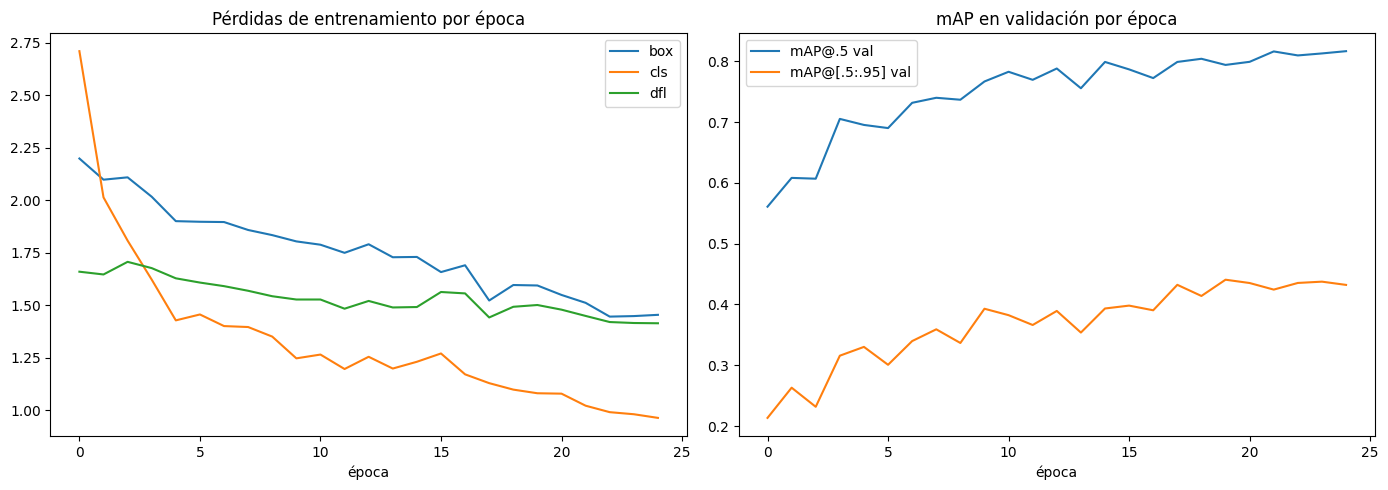

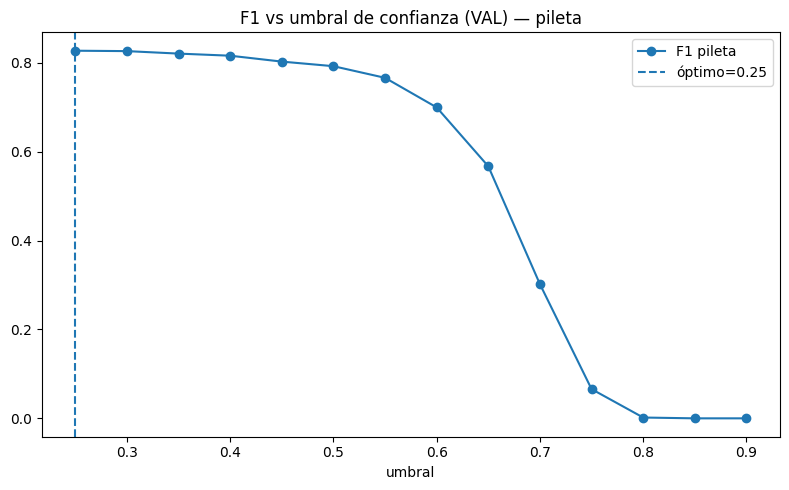

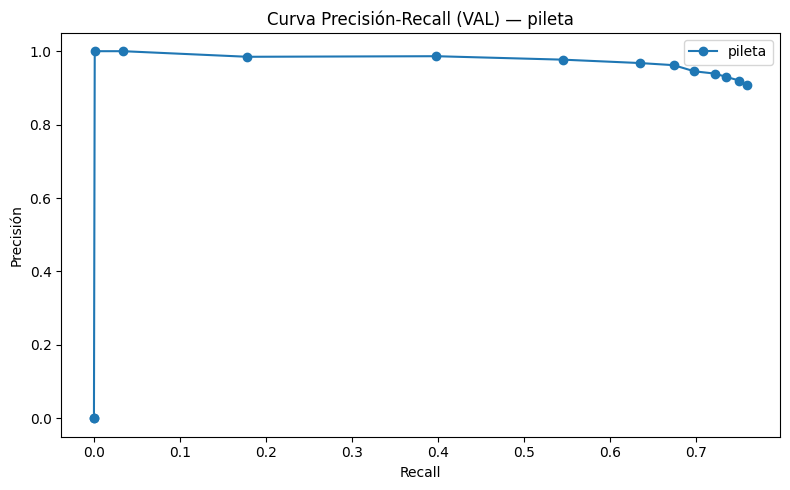

In [7]:
# ================= ETAPA 6 · Gráficos =================
# Qué hace: curvas de entrenamiento (results.csv), F1 vs umbral y curva PR
# solo pileta. Todo se guarda en PNG y se muestra.
df_res = pd.read_csv(RESULTS_CSV)
print("Épocas entrenadas:", len(df_res))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].plot(df_res["train/box_loss"], label="box")
ax[0].plot(df_res["train/cls_loss"], label="cls")
if "train/dfl_loss" in df_res:
    ax[0].plot(df_res["train/dfl_loss"], label="dfl")
ax[0].set_title("Pérdidas de entrenamiento por época")
ax[0].set_xlabel("época")
ax[0].legend()
ax[1].plot(df_res["metrics/mAP50(B)"], label="mAP@.5 val")
ax[1].plot(df_res["metrics/mAP50-95(B)"], label="mAP@[.5:.95] val")
ax[1].set_title("mAP en validación por época")
ax[1].set_xlabel("época")
ax[1].legend()
fig.tight_layout()
fig.savefig(RES_DIR / "curvas_entrenamiento.png", dpi=120)

sw = pd.DataFrame(SWEEP, columns=["thr", "P", "R", "F1"])
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(sw.thr, sw.F1, marker="o", label="F1 pileta")
ax.axvline(OPT_THR, linestyle="--", label=f"óptimo={OPT_THR:.2f}")
ax.set_title("F1 vs umbral de confianza (VAL) — pileta")
ax.set_xlabel("umbral")
ax.legend()
fig.tight_layout()
fig.savefig(RES_DIR / "f1_vs_umbral.png", dpi=120)

fig, ax = plt.subplots(figsize=(8, 5))  # curva PR: P vs R barriendo el umbral
ax.plot(sw.R, sw.P, marker="o", label="pileta")
ax.set_title("Curva Precisión-Recall (VAL) — pileta")
ax.set_xlabel("Recall")
ax.set_ylabel("Precisión")
ax.legend()
fig.tight_layout()
fig.savefig(RES_DIR / "curvas_pr.png", dpi=120)
print("Gráficos guardados en resultados/")




Comparativa guardada en resultados/bboxes_test/
Buscá a ojo: falsos positivos y piletas perdidas.


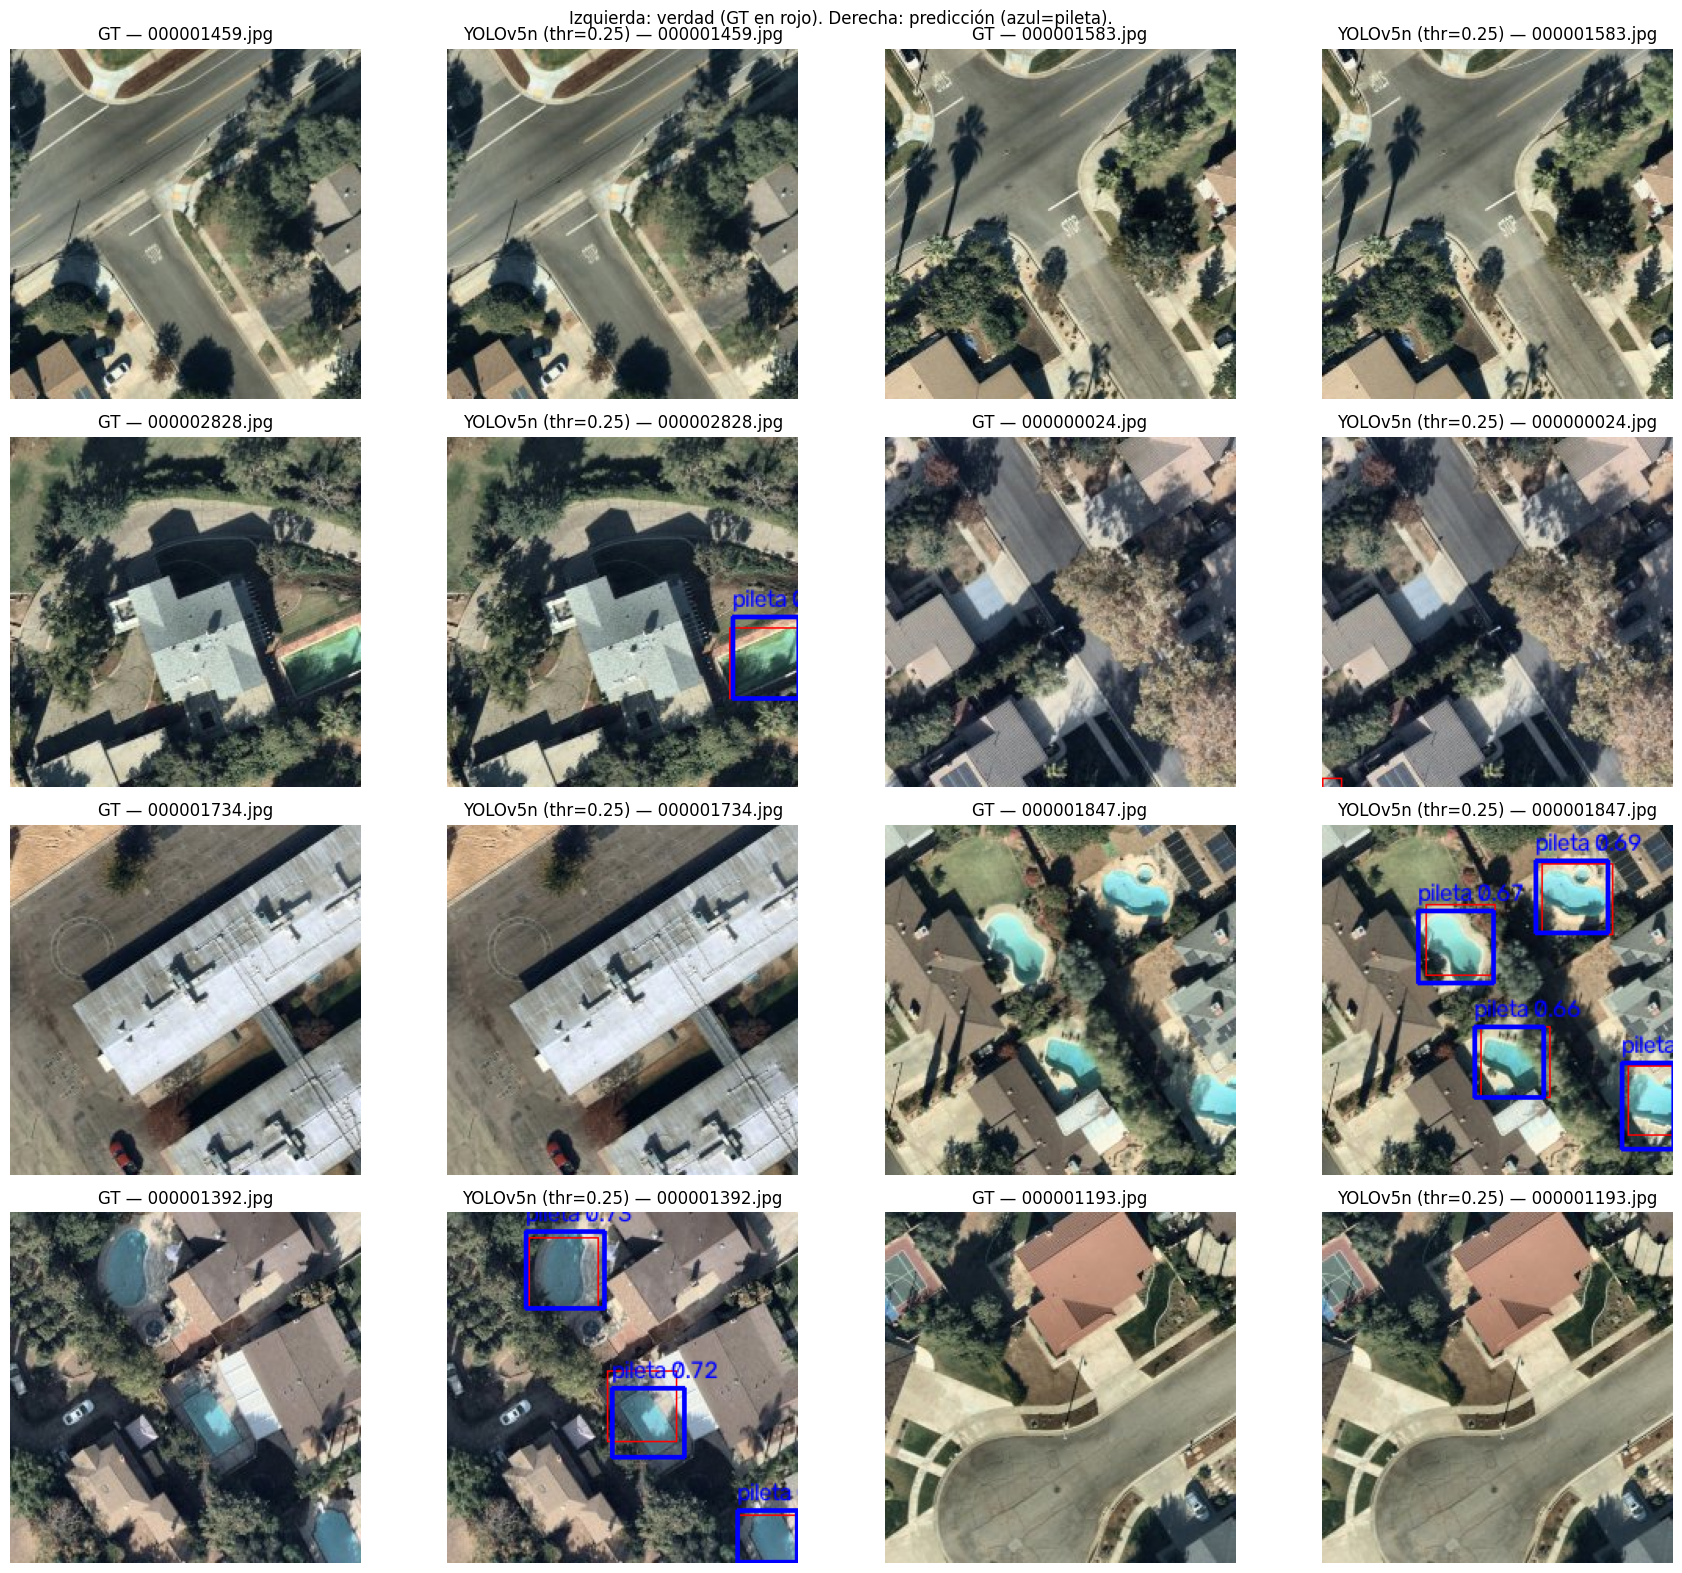

In [8]:
# ================= ETAPA 7 · Bounding boxes sobre el test etiquetado =================
# Qué hace: dibuja GT (rojo) vs predicción (azul=pileta) lado a lado
# en 8 imágenes de test. Es el control visual de que las métricas dicen la verdad.
import cv2

def dibujar(imagen_rgb, dets, gt=None):
    """dets: lista [(box, score)] pileta. Devuelve imagen anotada (OpenCV usa BGR)."""
    img = cv2.cvtColor(np.array(imagen_rgb), cv2.COLOR_RGB2BGR)
    color = (255, 0, 0)  # BGR: azul pileta
    if gt is not None:
        for b in gt:
            x1, y1, x2, y2 = map(int, b)
            cv2.rectangle(img, (x1, y1), (x2, y2), (0, 0, 255), 1)  # GT en rojo fino
    for b, s in dets:
        x1, y1, x2, y2 = map(int, b)
        cv2.rectangle(img, (x1, y1), (x2, y2), color, 2)
        cv2.putText(img, f"pileta {s:.2f}", (x1, max(0, y1 - 6)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 1)
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

(RES_DIR / "bboxes_test").mkdir(exist_ok=True)
_rnd.seed(SEED)
elegidas = _rnd.sample(range(len(imgs_test)), min(8, len(imgs_test)))
fig, axes = plt.subplots(4, 4, figsize=(18, 16))
for k, idx in enumerate(elegidas):
    ruta = imgs_test[idx]
    pil = Image.open(ruta).convert("RGB")
    axes[k // 2, (k % 2) * 2].imshow(np.array(pil))
    axes[k // 2, (k % 2) * 2].set_title(f"GT — {ruta.name}")
    axes[k // 2, (k % 2) * 2].axis("off")
    axes[k // 2, (k % 2) * 2 + 1].imshow(dibujar(pil, test_pred[idx], test_gt[idx]))
    axes[k // 2, (k % 2) * 2 + 1].set_title(f"YOLOv5n (thr={OPT_THR:.2f}) — {ruta.name}")
    axes[k // 2, (k % 2) * 2 + 1].axis("off")
fig.suptitle("Izquierda: verdad (GT en rojo). Derecha: predicción (azul=pileta).")
fig.tight_layout()
fig.savefig(RES_DIR / "bboxes_test" / "comparativa_gt_vs_pred.png", dpi=120)
print("Comparativa guardada en resultados/bboxes_test/")
print("Buscá a ojo: falsos positivos y piletas perdidas.")




Imágenes sin etiqueta: 0 en None
Galería guardada en resultados/galeria_10k.png
TODAS=False: solo galería de 50. Poné TODAS=True para el CSV completo.


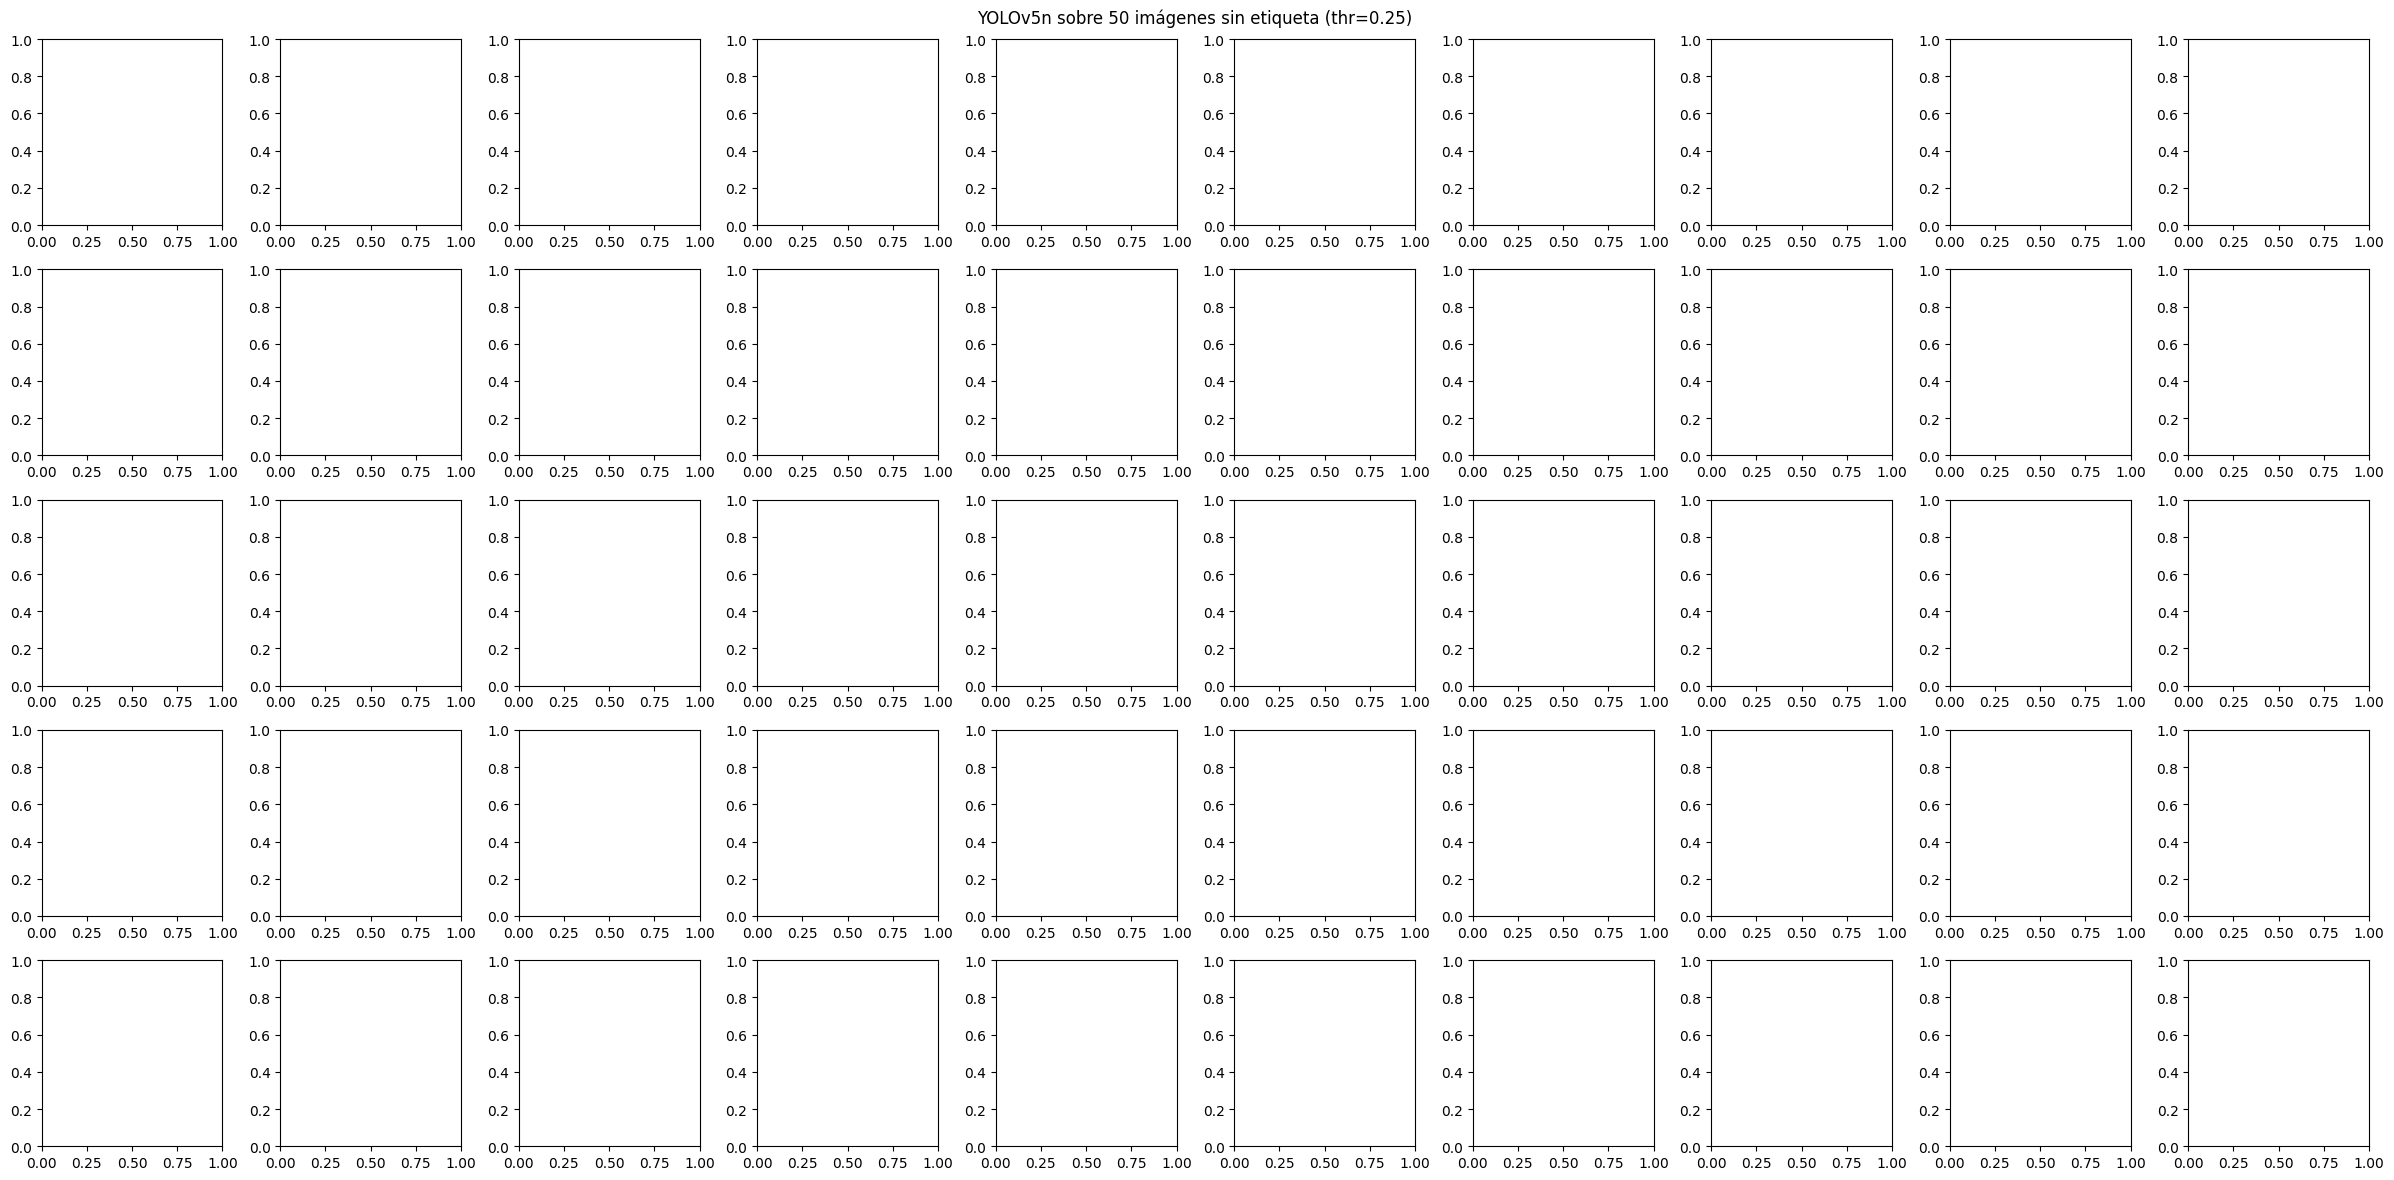

In [9]:
# ================= ETAPA 8 · Inferencia sobre las 10.2k sin etiquetas =================
# Qué hace: prueba el modelo en imágenes reales sin anotar (muestra de 50 para la
# galería; TODAS=True opcional para el CSV completo formato competencia).
from tqdm import tqdm

carpeta_test10k = None
for cand in [RUTA_DATASET / "test_data_images", RUTA_DATASET]:
    imgs = [p for p in cand.glob("*") if p.suffix.lower() in (".jpg", ".jpeg", ".png")]
    if len(imgs) > 1000:
        carpeta_test10k = cand
        break
print(f"Imágenes sin etiqueta: {len(imgs)} en {carpeta_test10k}")

_rnd.seed(SEED)
muestra10k = _rnd.sample(imgs, min(50, len(imgs)))
fig, axes = plt.subplots(5, 10, figsize=(24, 12))
for ax, ruta in zip(axes.flat, muestra10k):
    pil = Image.open(ruta).convert("RGB")
    boxes, scores, clss = predecir(ruta, conf=OPT_THR)
    dets = [(b, s) for b, s in zip(boxes, scores)]
    ax.imshow(dibujar(pil, dets))
    ax.set_title(ruta.name, fontsize=7)
    ax.axis("off")
fig.suptitle(f"YOLOv5n sobre 50 imágenes sin etiqueta (thr={OPT_THR:.2f})")
fig.tight_layout()
fig.savefig(RES_DIR / "galeria_10k.png", dpi=150)
print("Galería guardada en resultados/galeria_10k.png")

# --- Modo completo (opcional, ~30-40 min en T4): detecciones de TODAS en CSV ---
TODAS = False
if TODAS:
    print(f"Estimación: {len(imgs)} imgs x {ms_gpu / 1000:.2f} s ≈ {len(imgs) * ms_gpu / 1000 / 60:.0f} min")
    filas_csv = []
    for ruta in tqdm(imgs, desc="Detectando 10k"):
        boxes, scores, clss = predecir(ruta, conf=OPT_THR)
        for b, s in zip(boxes, scores):
            filas_csv.append({"image_id": ruta.name, "xmin": b[0], "ymin": b[1],
                              "xmax": b[2], "ymax": b[3],
                              "class": 0,  # 0=pileta (única clase)
                              "conf": float(s)})
    pd.DataFrame(filas_csv).to_csv(RES_DIR / "detecciones_10k.csv", index=False)
    print("CSV guardado en resultados/detecciones_10k.csv")
else:
    print("TODAS=False: solo galería de 50. Poné TODAS=True para el CSV completo.")




In [10]:
# ================= ETAPA 9 · Export ONNX + trade-off =================
# Qué hace: exporta a ONNX UNA sola vez (si ya existe lo reutiliza) y mide con
# números reales qué se gana en peso/velocidad CPU y qué se pierde de mAP.
# Es el ÚNICO lugar donde se exporta el modelo; la Etapa 11 solo empaqueta.
print("--- Exportando a ONNX (una sola vez) ---")
onnx_path = RUNS_DIR / "yolov5n" / "weights" / "best.onnx"
if not onnx_path.exists():
    onnx_path = Path(modelo.export(format="onnx"))  # devuelve la ruta del .onnx
else:
    print("ONNX ya existente, se reutiliza sin re-exportar:", onnx_path)
onnx_path = Path(onnx_path)
print("ONNX en:", onnx_path, f"({onnx_path.stat().st_size / 1e6:.2f} MB vs {MB:.2f} MB del .pt)")

print("--- FPS en CPU: .pt vs .onnx (10 imágenes) ---")
def fps_cpu(m, n=10):
    t0 = time.time()
    for r in imgs_test[:n]:
        m.predict(source=str(r), imgsz=IMG_SIZE, conf=OPT_THR, verbose=False, device="cpu")
    return n / (time.time() - t0)
fps_pt = fps_cpu(modelo)
modelo_onnx = YOLO(str(onnx_path))
fps_onnx = fps_cpu(modelo_onnx)
print(f"FPS CPU .pt={fps_pt:.1f} | .onnx={fps_onnx:.1f}")

# BUG CORREGIDO: antes se comparaba el ONNX en 100 imagenes de VAL contra el .pt
# en TEST completo. Eran conjuntos distintos, asi que el delta no significaba nada.
# Ahora los dos modelos se miden sobre EL MISMO subconjunto de test.
print("--- mAP@.5 .pt vs .onnx sobre el MISMO subconjunto de test ---")
sub_cmp = imgs_test[:100]
modelo_onnx = YOLO(str(onnx_path))
pv_pt, tv_pt = coleccionar_pares(sub_cmp, conf=0.001, device="cpu")
map_pt_sub = float(MeanAveragePrecision(iou_thresholds=[0.5],
                                        class_metrics=True)(pv_pt, tv_pt)["map"])
pv, tv = coleccionar_pares(sub_cmp, conf=0.001, modelo_ref=modelo_onnx, device="cpu")
map_onnx = float(MeanAveragePrecision(iou_thresholds=[0.5],
                                      class_metrics=True)(pv, tv)["map"])
print(f"Subconjunto: {len(sub_cmp)} imágenes de test (identico para ambos)")
print(f"mAP@.5 .pt={map_pt_sub:.4f} | .onnx={map_onnx:.4f} "
      f"(delta={map_onnx - map_pt_sub:+.4f})")
print("Esperado: delta ~0. El export sin cuantizar mantiene los pesos en FP32,")
print("es la misma red en otro formato. Un delta grande indica error de medición.")

pd.DataFrame([
    ("peso_pt_MB", MB), ("peso_onnx_MB", onnx_path.stat().st_size / 1e6),
    ("fps_cpu_pt", fps_pt), ("fps_cpu_onnx", fps_onnx),
    ("map50_pt_sub", map_pt_sub), ("map50_onnx_sub", map_onnx),
    ("delta_map50", map_onnx - map_pt_sub),
    ("n_imgs_comparacion", len(sub_cmp)),
    ("map50_pt_test_completo", float(map50["map"])),
], columns=["metrica", "valor"]).to_csv(RES_DIR / "trade_off_onnx.csv", index=False)
print("Tabla guardada en resultados/trade_off_onnx.csv")




--- Exportando a ONNX (una sola vez) ---
Ultralytics 8.4.164 🚀 Python-3.13.15 torch-2.11.0+cu128 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLOv5n summary (fused): 84 layers, 2,503,139 parameters, 0 gradients

PyTorch: starting from '/content/runs/yolov5n/weights/best.pt' with input shape (1, 3, 320, 320) BCHW and output shape(s) (1, 5, 2100) (5.0 MB)
requirements: Ultralytics requirement ['onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 10 packages in 213ms
Prepared 2 packages in 22ms
Installed 2 packages in 5ms
 + colorama==0.4.6
 + onnxslim==0.1.96

requirements: AutoUpdate success ✅ 0.4s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.23.0 opset 18...
ONNX: slimming with onnxslim 0.1.96...
ONNX: export success ✅ 1.8s, saved a

In [11]:
# ================= ETAPA 10 · Informe final =================
# Qué hace: escribe informe_final.md con los números reales, el umbral óptimo,
# el veredicto y mejoras futuras. Sin inventar ningún dato.
mejor_epoca = int(df_res["metrics/mAP50-95(B)"].idxmax()) + 1
informe = f"""# Informe final — YOLOv5n (piletas, 1 clase)

## Datos
- Imágenes anotadas: {len(info_imgs)} (XML Pascal VOC) | Anotaciones: {len(df_anot)}
- Split 70/15/15 estratificado por pileta: train={len(df_train)}, val={len(df_val)}, test={len(df_test)}
- Clase YOLO: 0=pileta (XML {CLASE_PILETA_XML!r}->pileta, resto descartado)

## Entrenamiento
- Pesos iniciales COCO (yolov5nu.pt), imgsz={IMG_SIZE}, batch={BATCH}, épocas máx={EPOCHS}
- Épocas ejecutadas: {len(df_res)} | Mejor época (val mAP50-95): {mejor_epoca}

## Métricas en TEST (umbral óptimo {OPT_THR:.2f}, IoU 0.5)
- mAP@[.5:.95]={float(map_total['map']):.4f} | mAP@.5={float(map50['map']):.4f} | mAP@.75={float(map75['map']):.4f}
- AP pileta@.5={float(map50['map']):.4f}
- pileta: P={M['P']:.3f} R={M['R']:.3f} F1={M['F1']:.3f} IoU={M['IoU_prom']:.3f}

## Costo
- Parámetros: {PARAMS_M:.2f} M | Peso .pt: {MB:.2f} MB | GFLOPs: {GFLOPS:.2f}
- GPU: {ms_gpu:.1f} ms/img ({1000 / ms_gpu:.1f} FPS) | CPU: {ms_cpu:.1f} ms/img
- ONNX: ver resultados/trade_off_onnx.csv
- Modelo minimizado: nc=1 reduce la cabeza Detect vs nc=2.

## Veredicto
- YOLOv5n (~2.5M params) es el más chico y rápido de entrenar de la familia: ideal para
  Colab gratis y para inferencia en CPU.
- El umbral {OPT_THR:.2f} maximiza el F1 en VAL (elegido en VAL, no en TEST, para no
  contaminar la evaluación).

## Mejoras futuras
1. TTA con flip horizontal en la demo (+1/2 puntos mAP, x2 tiempo).
2. imgsz=640 si hay más VRAM (ayuda a piletas chicas/lejanas).
3. Más aumentos (mosaic ya viene activo en YOLO; sumar copy-paste si hay pocas piletas).
4. Barrer hiperparámetros (lr, weight_decay) con 2-3 corridas cortas.
5. Exportar a TFLite/OpenVINO para CPU/móvil si la demo sale de Colab.
"""
(RES_DIR / "informe_final.md").write_text(informe)
print(informe)




# Informe final — YOLOv5n (piletas, 1 clase)

## Datos
- Imágenes anotadas: 3748 (XML Pascal VOC) | Anotaciones: 16172
- Split 70/15/15 estratificado por pileta: train=1311, val=1312, test=1125
- Clase YOLO: 0=pileta (XML '2'->pileta, resto descartado)

## Entrenamiento
- Pesos iniciales COCO (yolov5nu.pt), imgsz=320, batch=8, épocas máx=25
- Épocas ejecutadas: 25 | Mejor época (val mAP50-95): 20

## Métricas en TEST (umbral óptimo 0.25, IoU 0.5)
- mAP@[.5:.95]=0.4203 | mAP@.5=0.7846 | mAP@.75=0.4003
- AP pileta@.5=0.7846
- pileta: P=0.891 R=0.741 F1=0.809 IoU=0.787

## Costo
- Parámetros: 2.51 M | Peso .pt: 5.23 MB | GFLOPs: 0.90
- GPU: 9.5 ms/img (104.8 FPS) | CPU: 49.2 ms/img
- ONNX: ver resultados/trade_off_onnx.csv
- Modelo minimizado: nc=1 reduce la cabeza Detect vs nc=2.

## Veredicto
- YOLOv5n (~2.5M params) es el más chico y rápido de entrenar de la familia: ideal para
  Colab gratis y para inferencia en CPU.
- El umbral 0.25 maximiza el F1 en VAL (elegido en VAL, no en TEST, 

In [12]:
# ================= ETAPA 11 · Empaquetar y descargar =================
# Qué hace: junta modelos, métricas, gráficos e informe en un ZIP descargable.
# No exporta nada: reutiliza BEST_PT (Etapa 4) y onnx_path (Etapa 9).
(RES_DIR / "modelos").mkdir(exist_ok=True)
shutil.copy2(BEST_PT, RES_DIR / "modelos" / "yolov5n_best.pt")
if onnx_path.exists():
    shutil.copy2(onnx_path, RES_DIR / "modelos" / "yolov5n_best.onnx")
shutil.copy2(YAML_PATH, RES_DIR / "modelos" / "data.yaml")

zip_path = shutil.make_archive("/content/yolov5n_piletas_resultados", "zip",
                               root_dir=BASE, base_dir="resultados")
print(f"ZIP: {zip_path} ({Path(zip_path).stat().st_size / 1e6:.1f} MB)")
for p in sorted(RES_DIR.rglob("*")):
    if p.is_file():
        print(" -", p.relative_to(RES_DIR))
try:
    from google.colab import files
    files.download(zip_path)
except Exception:
    print("No estamos en Colab: el ZIP quedó en", zip_path)




ZIP: /content/yolov5n_piletas_resultados.zip (18.8 MB)
 - bboxes_test/comparativa_gt_vs_pred.png
 - curvas_entrenamiento.png
 - curvas_pr.png
 - eda_ejemplos.png
 - f1_vs_umbral.png
 - galeria_10k.png
 - informe_final.md
 - metricas.csv
 - modelos/data.yaml
 - modelos/yolov5n_best.onnx
 - modelos/yolov5n_best.pt
 - trade_off_onnx.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ================= ETAPA 12 · Demo: subí UNA imagen y detectá =================
# Qué hace: pegás un link http (o subís el archivo) y te devuelve la imagen
# original con los boxes + la clasificación legible. Los boxes que da YOLO ya
# vienen en píxeles originales: se dibujan directo, sin reescalado manual.
import requests
from io import BytesIO

URL_IMAGEN = ""  # <- PEGAR ACÁ el link directo a un .jpg/.png (o dejar vacío para subir archivo)

if URL_IMAGEN.strip():
    print("Descargando:", URL_IMAGEN)
    resp = requests.get(URL_IMAGEN, headers={"User-Agent": "Mozilla/5.0"}, timeout=20)
    resp.raise_for_status()
    pil_demo = Image.open(BytesIO(resp.content)).convert("RGB")
    nombre_demo = URL_IMAGEN.split("/")[-1].split("?")[0] or "demo.jpg"
else:
    print("Sin URL: subí la imagen desde tu PC.")
    try:
        from google.colab import files
        subido = files.upload()
        nombre_demo = next(iter(subido))
        pil_demo = Image.open(BytesIO(subido[nombre_demo])).convert("RGB")
    except Exception:
        raise SystemExit("Ni URL ni upload disponible: pegá un link en URL_IMAGEN.")
print(f"Imagen: {nombre_demo} ({pil_demo.size[0]}x{pil_demo.size[1]})")

tmp_demo = BASE / "_demo_tmp.jpg"
pil_demo.save(tmp_demo)
boxes, scores, clss = predecir(tmp_demo, conf=OPT_THR)
dets_demo = [(b, s) for b, s in zip(boxes, scores)]

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(dibujar(pil_demo, dets_demo))
ax.axis("off")
ax.set_title(f"YOLOv5n pileta (thr={OPT_THR:.2f}) — {nombre_demo}")
fig.tight_layout()
fig.savefig(RES_DIR / "demo_resultado.png", dpi=150)

n_p = len(dets_demo)
if n_p == 0:
    print(f"No se detectó ninguna pileta con confianza >= {OPT_THR:.2f}. "
          "Probá bajar el umbral o con otra imagen.")
else:
    sp = ", ".join(f"{s:.2f}" for _, s in dets_demo)
    print(f"Detectado: {n_p} pileta(s) [{sp}]")
tmp_demo.unlink(missing_ok=True)


Sin URL: subí la imagen desde tu PC.
